# Exploratory Data Analysis: Stock Capitalization and PEG

Analyze the latest supplied `data/equity_data.csv`. Keep the source unchanged and export a three-column complete-case modeling dataset to `data/stocks_clean.csv`.

This notebook evaluates schema, missingness, numerical validity, distributions, tail observations, missingness-related selection, and capitalization/PEG relationships. It does not fit models or a scaler. Historical fallback PEG observations are not contemporaneous current measurements.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/equity_data.csv").exists():
    ROOT = ROOT.parent
INPUT = ROOT / "data/equity_data.csv"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
COLUMNS = ["Ticker", "Market_capital", "PEG ratio"]
source_hash = hashlib.sha256(INPUT.read_bytes()).hexdigest()
raw = pd.read_csv(INPUT, keep_default_na=False)
if raw.columns.tolist() != COLUMNS:
    raise ValueError(f"Expected columns in this order: {COLUMNS}")
if raw.empty:
    raise ValueError("The input dataset is empty.")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"Input: {INPUT.relative_to(ROOT)}")
print(f"Source SHA-256: {source_hash}")
print(f"Shape: {raw.shape}")
print(f"Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}, matplotlib {matplotlib.__version__}")
display(raw.head(10))


Matplotlib is building the font cache; this may take a moment.


Input: data/equity_data.csv
Source SHA-256: 83ce5e0b13716944721d7a700a7b8f475960188a849be6e42657515454019ec7
Shape: (1958, 3)
Python 3.13.5, pandas 2.2.3, numpy 2.1.3, matplotlib 3.10.0


,Ticker,Market_capital,PEG ratio
0,RLJ,2.023031e+09,4.680005
1,FVR,5.152375e+08,
2,BKD,2.214870e+09,
3,RRR,5.268382e+09,6.18966
4,IVT,2.478155e+09,2.987124
5,HOG,3.443334e+09,1.68004
6,FWRG,8.320736e+08,37.802195
7,IART,1.167793e+09,
8,IBP,5.633310e+09,1.506817
9,RDNT,6.168862e+09,98.457005


## 1. Schema and Data Quality

Convert numerical fields explicitly and distinguish original blanks from parsing failures. Normalize ticker whitespace/case without removing rows. Flag all occurrences of duplicated tickers rather than arbitrarily selecting one record. Nonfinite values and nonpositive market capitalization are invalid. Nonpositive PEG values are unsuitable for the primary positive-PEG style interpretation and are excluded from the modeling export if present, with reasons recorded.


In [2]:
data = raw.copy()
data["Ticker"] = data["Ticker"].astype("string").str.strip().str.upper()
original_missing = pd.DataFrame({col: raw[col].astype("string").str.strip().eq("") for col in COLUMNS})
parse_failures = {}
for col in COLUMNS[1:]:
    data[col] = pd.to_numeric(raw[col], errors="coerce")
    parse_failures[col] = int((data[col].isna() & ~original_missing[col]).sum())
quality = pd.DataFrame({
    "Column": COLUMNS,
    "Original missing": [int(original_missing[col].sum()) for col in COLUMNS],
    "Numeric parsing failures": [0] + [parse_failures[col] for col in COLUMNS[1:]],
    "Nonfinite numeric values": [0] + [int((data[col].notna() & ~np.isfinite(data[col])).sum()) for col in COLUMNS[1:]],
})
quality["Original missing percent"] = quality["Original missing"] / len(data) * 100
quality.to_csv(OUT / "eda_data_quality.csv", index=False)
duplicate_ticker = data["Ticker"].duplicated(keep=False) & data["Ticker"].ne("")
print(f"Duplicate ticker rows: {duplicate_ticker.sum()}")
print(f"Exact duplicate rows: {raw.duplicated().sum()}")
print(f"Nonpositive market capitalization: {(data['Market_capital'] <= 0).sum()}")
print(f"Nonpositive PEG: {(data['PEG ratio'] <= 0).sum()}")
display(quality)


Duplicate ticker rows: 0
Exact duplicate rows: 0
Nonpositive market capitalization: 0
Nonpositive PEG: 0


,Column,Original missing,Numeric parsing failures,Nonfinite numeric values,Original missing percent
0,Ticker,0,0,0,0.000000
1,Market_capital,0,0,0,0.000000
2,PEG ratio,797,0,0,40.704801


## 2. Descriptive Statistics and Missingness

Market capitalization uses the source file's numerical unit; the three-column file itself does not verify its currency, unit, or observation date. Figures therefore label it as source units. Do not infer full-market capitalization categories from sample-relative sizes.


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
Market_capital,1958.0,1.838728e+09,1.996305e+09,4.704041e+06,5.403988e+07,1.487053e+08,4.181133e+08,1.063996e+09,2.604428e+09,5.880965e+09,8.953323e+09,1.458955e+10,1.931303
PEG ratio,1161.0,1.024929e+01,9.147316e+01,3.873000e-03,1.306860e-02,8.100600e-02,5.205860e-01,1.492798e+00,4.047014e+00,3.066762e+01,9.630457e+01,2.921253e+03,28.412277


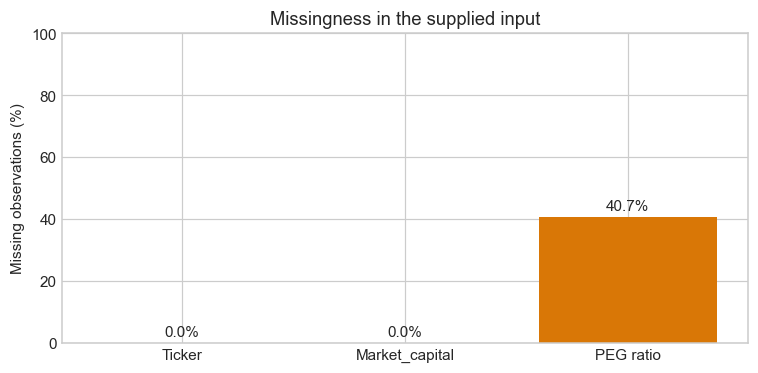

In [3]:
description = data[COLUMNS[1:]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
description["skewness"] = data[COLUMNS[1:]].skew()
description.to_csv(OUT / "eda_descriptive_statistics.csv")
display(description)
fig, ax = plt.subplots(figsize=(7, 3.5))
missing_pct = original_missing.mean() * 100
ax.bar(missing_pct.index, missing_pct.values, color=["#94a3b8", "#2563eb", "#d97706"])
ax.set(ylabel="Missing observations (%)", ylim=(0, 100), title="Missingness in the supplied input")
for i, value in enumerate(missing_pct):
    ax.text(i, value + 2, f"{value:.1f}%", ha="center")
save_figure(fig, "eda_missingness.png")


## 3. Missingness and Sample Selection

Compare capitalization distributions of stocks with and without valid positive PEG. This is a descriptive selection diagnostic, not proof of why PEG is missing. The complete-case sample may not represent the entire supplied universe.


,count,mean,median,min,max
PEG availability,,,,,
Missing or invalid PEG,797,1.467072e+09,7.034338e+08,4.704041e+06,1.458137e+10
Valid positive PEG,1161,2.093861e+09,1.379027e+09,2.087562e+07,1.458955e+10


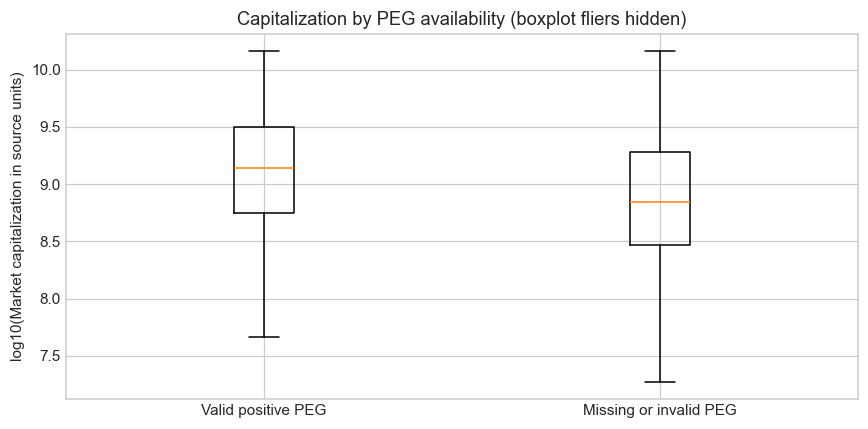

In [4]:
cap_valid = data["Market_capital"].notna() & np.isfinite(data["Market_capital"]) & data["Market_capital"].gt(0)
peg_valid = data["PEG ratio"].notna() & np.isfinite(data["PEG ratio"]) & data["PEG ratio"].gt(0)
comparison = data.loc[cap_valid, ["Market_capital"]].copy()
comparison["PEG availability"] = np.where(peg_valid.loc[cap_valid], "Valid positive PEG", "Missing or invalid PEG")
selection = comparison.groupby("PEG availability")["Market_capital"].agg(["count", "mean", "median", "min", "max"])
selection.to_csv(OUT / "eda_missingness_by_capitalization.csv")
display(selection)
fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Valid positive PEG", "Missing or invalid PEG"]
values = [np.log10(comparison.loc[comparison['PEG availability'].eq(label), 'Market_capital']) for label in labels]
ax.boxplot(values, tick_labels=labels, showfliers=False)
ax.set(ylabel="log10(Market capitalization in source units)", title="Capitalization by PEG availability (boxplot fliers hidden)")
save_figure(fig, "eda_selection_by_capitalization.png")


## 4. Cleaning and Modeling Sample

Export only rows with a nonblank unique ticker, finite positive capitalization, and finite positive PEG. Do not impute PEG, winsorize, trim tails, or standardize here. Keep source order and the original three column names. Record excluded source rows (1-based CSV line numbers, including the header) and all applicable reasons in a separate output.


In [5]:
reasons = pd.DataFrame({
    "Missing ticker": data["Ticker"].isna() | data["Ticker"].eq(""),
    "Duplicated ticker": duplicate_ticker,
    "Missing or nonnumeric capitalization": data["Market_capital"].isna(),
    "Nonfinite capitalization": data["Market_capital"].notna() & ~np.isfinite(data["Market_capital"]),
    "Nonpositive capitalization": data["Market_capital"].le(0),
    "Missing or nonnumeric PEG": data["PEG ratio"].isna(),
    "Nonfinite PEG": data["PEG ratio"].notna() & ~np.isfinite(data["PEG ratio"]),
    "Nonpositive PEG": data["PEG ratio"].le(0),
}).fillna(False)
keep = ~reasons.any(axis=1)
clean = data.loc[keep, COLUMNS].copy()
if len(clean) < 9:
    raise ValueError("Fewer than nine valid rows remain; inspect the data before modeling.")
excluded = raw.loc[~keep].copy()
excluded.insert(0, "Source CSV line", excluded.index + 2)
excluded["Exclusion reasons"] = reasons.loc[~keep].apply(lambda row: "; ".join(row.index[row]), axis=1)
excluded.to_csv(OUT / "eda_excluded_stocks.csv", index=False)
clean.to_csv(ROOT / "data/stocks_clean.csv", index=False)
print(f"Source rows: {len(data):,}; retained: {len(clean):,}; excluded: {(~keep).sum():,}")
print("No outlier removal, imputation, or scaling applied.")
assert len(clean) + len(excluded) == len(raw)
assert clean.columns.tolist() == COLUMNS


Source rows: 1,958; retained: 1,161; excluded: 797
No outlier removal, imputation, or scaling applied.


## 5. Distributions and Tail Observations

Show raw and log10 views using the same complete-case sample. Log views reveal structure compressed by large observations; they do not remove observations. The 1.5 x IQR rule is a descriptive flag, not an automatic deletion criterion. Compare flags on raw and log scales because they answer different questions.


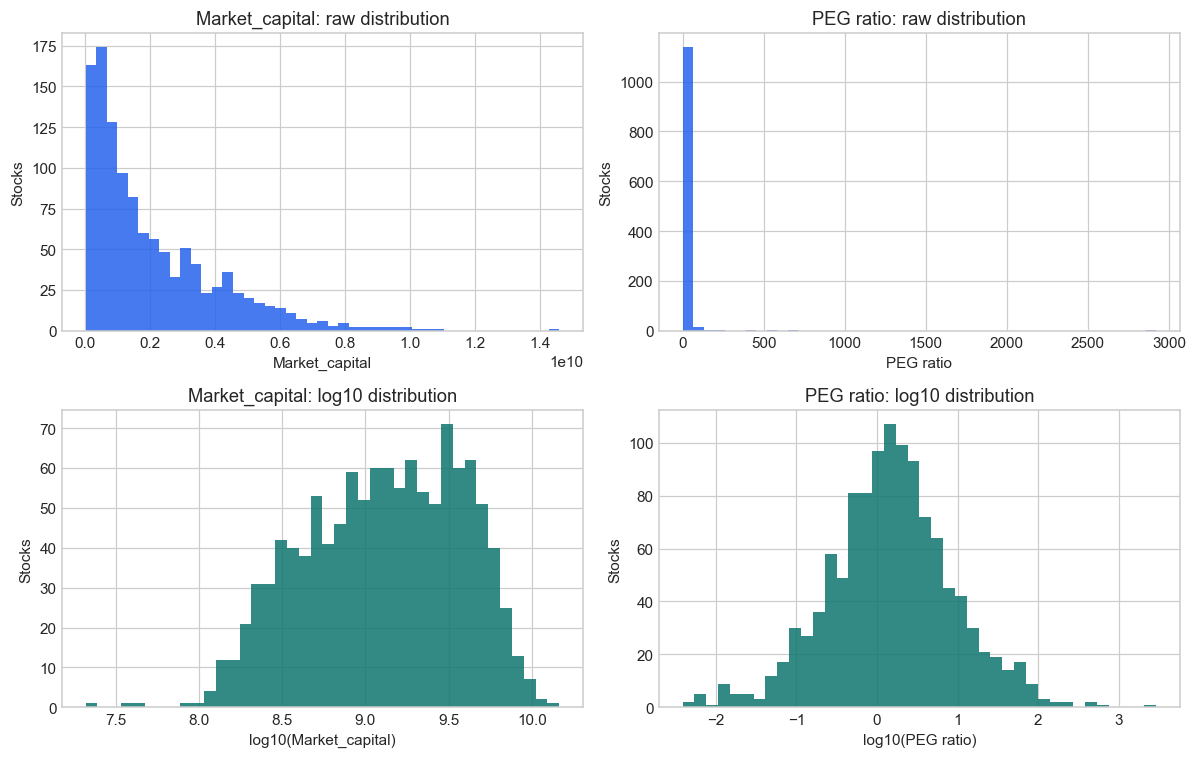

,Feature,Scale,Lower fence,Upper fence,Flagged rows
0,Market_capital,raw,-3.310041e+09,6.997222e+09,32
1,Market_capital,log10,7.617357e+00,1.062290e+01,2
2,PEG ratio,raw,-4.769056e+00,9.336656e+00,162
3,PEG ratio,log10,-1.619471e+00,1.943098e+00,42


Ten largest PEG observations (retained):


,Ticker,Market_capital,PEG ratio
69,USPH,1.499974e+09,2921.252618
193,COTY,3.622320e+09,650.029709
406,AVO,1.028906e+09,537.407304
1570,ROG,2.332804e+09,409.427350
1035,INTT,1.890767e+08,258.758189
477,BPRN,3.011822e+08,220.236612
499,BXC,5.056905e+08,182.518882
1311,NRC,5.714960e+08,157.830567
1239,MRAM,3.297663e+08,121.940122
1732,TBCH,3.033700e+08,112.069276


Ten largest market capitalization observations:


,Ticker,Market_capital,PEG ratio
167,BTSG,1.458955e+10,1.038598
1232,MOG/A,1.089444e+10,0.558227
110,LTH,1.066417e+10,0.323859
173,UMBF,1.024373e+10,1.218849
85,CTRE,9.901795e+09,1.525460
70,TGTX,9.779264e+09,0.149685
28,RHP,9.577855e+09,13.317583
1366,ONB,9.522645e+09,1.496345
1070,JXN,9.207328e+09,0.155416
131,KRYS,9.181191e+09,3.921183


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, col in enumerate(COLUMNS[1:]):
    axes[0, j].hist(clean[col], bins=45, color="#2563eb", alpha=.85)
    axes[0, j].set(title=f"{col}: raw distribution", xlabel=col, ylabel="Stocks")
    axes[1, j].hist(np.log10(clean[col]), bins=40, color="#0f766e", alpha=.85)
    axes[1, j].set(title=f"{col}: log10 distribution", xlabel=f"log10({col})", ylabel="Stocks")
save_figure(fig, "eda_feature_distributions.png")

flags = clean.copy()
threshold_rows = []
for col in COLUMNS[1:]:
    for scale, values in [("raw", clean[col]), ("log10", np.log10(clean[col]))]:
        q1, q3 = values.quantile([.25, .75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flag = values.lt(lower) | values.gt(upper)
        flags[f"{col} {scale} IQR flag"] = flag
        threshold_rows.append({"Feature": col, "Scale": scale, "Lower fence": lower,
                               "Upper fence": upper, "Flagged rows": int(flag.sum())})
thresholds = pd.DataFrame(threshold_rows)
thresholds.to_csv(OUT / "eda_outlier_thresholds.csv", index=False)
flags.to_csv(OUT / "eda_outlier_flags.csv", index=False)
display(thresholds)
print("Ten largest PEG observations (retained):")
display(clean.nlargest(10, "PEG ratio"))
print("Ten largest market capitalization observations:")
display(clean.nlargest(10, "Market_capital"))


## 6. Relationships and Transformation Sensitivity

Report Pearson correlation on raw and log10 features and Spearman rank correlation. These describe association, not causality or predictive performance. Neither PEG alone nor K-means cluster numbers establish a Morningstar investment-style classification.


,Measure,Correlation
0,"Pearson, raw",-0.013535
1,"Pearson, log10",0.033071
2,Spearman,0.027608


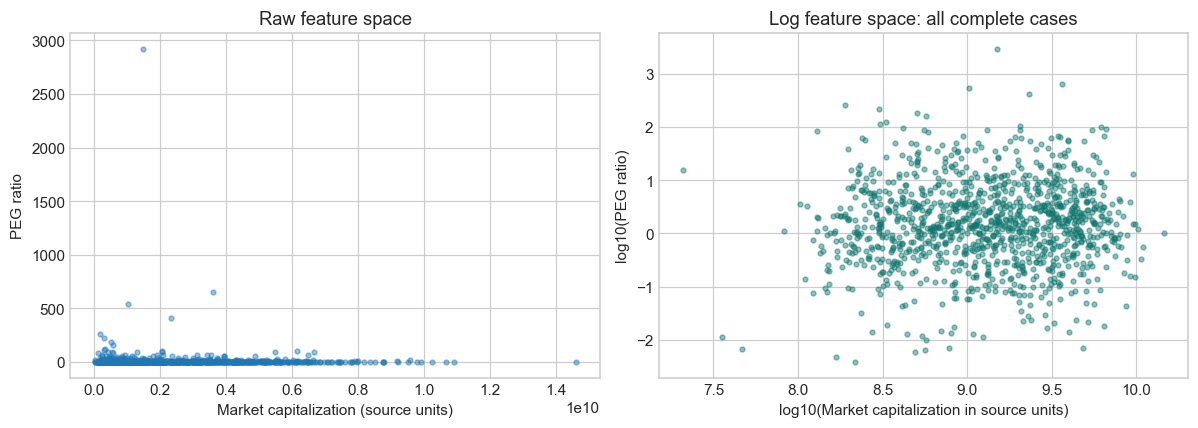

In [7]:
correlations = pd.DataFrame([
    {"Measure": "Pearson, raw", "Correlation": clean["Market_capital"].corr(clean["PEG ratio"])},
    {"Measure": "Pearson, log10", "Correlation": np.log10(clean["Market_capital"]).corr(np.log10(clean["PEG ratio"]))},
    {"Measure": "Spearman", "Correlation": clean["Market_capital"].rank().corr(clean["PEG ratio"].rank())},
])
correlations.to_csv(OUT / "eda_correlations.csv", index=False)
display(correlations)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(clean["Market_capital"], clean["PEG ratio"], s=10, alpha=.45)
axes[0].set(xlabel="Market capitalization (source units)", ylabel="PEG ratio", title="Raw feature space")
axes[1].scatter(np.log10(clean["Market_capital"]), np.log10(clean["PEG ratio"]), s=10, alpha=.45, color="#0f766e")
axes[1].set(xlabel="log10(Market capitalization in source units)", ylabel="log10(PEG ratio)", title="Log feature space: all complete cases")
save_figure(fig, "eda_feature_relationships.png")


## 7. Optional PEG Provenance Check

Use the collection log only when ticker coverage, uniqueness, and numerical PEG values match the supplied input. A matching log supports the recorded retrieval method and observation dates; file equality is not independent verification of the data vendor. Do not treat missing provenance as current data.


In [8]:
provenance_status = "No matching collection log available. Observation dates are unverified."
provenance_counts = {}
log_path = OUT / "equity_data_collection_log.csv"
if log_path.exists():
    log = pd.read_csv(log_path)
    required = {"Yahoo Symbol", "PEG ratio", "Selection", "As Of Date"}
    if required.issubset(log.columns) and not log["Yahoo Symbol"].duplicated().any():
        expected_symbols = data["Ticker"].str.replace(r"[./]", "-", regex=True)
        indexed = log.set_index("Yahoo Symbol")
        logged_peg = pd.to_numeric(expected_symbols.map(indexed["PEG ratio"]), errors="coerce")
        matching = expected_symbols.isin(indexed.index).all() and np.allclose(data["PEG ratio"], logged_peg, equal_nan=True)
        if matching:
            matched = indexed.reindex(expected_symbols.to_list())
            provenance_counts = {str(k): int(v) for k, v in matched["Selection"].value_counts().items()}
            provenance_status = "Collection log matches input ticker coverage and PEG values."
            dates = pd.to_datetime(matched["As Of Date"], errors="coerce")
            print(f"Recorded PEG observation dates: {dates.min()} to {dates.max()}")
            display(matched["Selection"].value_counts().rename_axis("Selection").to_frame("Rows"))
        else:
            provenance_status = "Collection log does not match the input; dates are not attributed to this dataset."
print(provenance_status)


Recorded PEG observation dates: 2025-03-31 00:00:00 to 2026-11-17 00:00:00


,Rows
Selection,
current,1036
unavailable,797
historical_fallback,125


Collection log matches input ticker coverage and PEG values.


## 8. Findings and Modeling Implications

The following summary is generated from the actual input. The recommended next step is to compare raw-versus-log feature specifications with scaling fitted within the appropriate training procedure. Do not fit K-means here or interpret missing PEG as a cheap valuation. Retain extreme PEG observations in the baseline and assess sensitivity during modeling. Very high PEG can reflect a small growth denominator; this dataset cannot identify the cause.


In [9]:
available_median = comparison.loc[comparison["PEG availability"].eq("Valid positive PEG"), "Market_capital"].median()
unavailable_median = comparison.loc[comparison["PEG availability"].eq("Missing or invalid PEG"), "Market_capital"].median()
metrics = {
    "input_file": str(INPUT.relative_to(ROOT)), "source_sha256": source_hash,
    "source_rows": len(raw), "modeling_rows": len(clean), "excluded_rows": len(excluded),
    "missing_peg_rows": int(data["PEG ratio"].isna().sum()),
    "missing_peg_percent": float(data["PEG ratio"].isna().mean() * 100),
    "peg_median": float(clean["PEG ratio"].median()), "peg_mean": float(clean["PEG ratio"].mean()),
    "peg_max": float(clean["PEG ratio"].max()),
    "capitalization_median_with_valid_peg": float(available_median),
    "capitalization_median_without_valid_peg": float(unavailable_median),
    "provenance_status": provenance_status, "provenance_counts": provenance_counts,
}
(OUT / "eda_summary.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
summary = f"""# EDA Findings

- Input: `{metrics['input_file']}`; {len(raw):,} stocks.
- Missing PEG: {metrics['missing_peg_rows']:,} ({metrics['missing_peg_percent']:.2f}%).
- Complete-case modeling sample: {len(clean):,}; excluded rows: {len(excluded):,}.
- PEG median: {metrics['peg_median']:.4f}; mean: {metrics['peg_mean']:.4f}; maximum: {metrics['peg_max']:.4f}.
- Median capitalization with valid PEG: {available_median:,.2f} source units.
- Median capitalization without valid PEG: {unavailable_median:,.2f} source units.
- Provenance: {provenance_status}
- Recorded selection counts: {provenance_counts}.

## Decisions

Use `data/stocks_clean.csv` as the positive-PEG complete-case baseline. Keep all tail observations; IQR flags are diagnostic only. Do not impute missing PEG or scale features during EDA. Compare log transformations and scaling in the modeling stage, fitting preprocessing within training when evaluating held-out performance.

## Limitations

Complete-case selection can change the capitalization mix. PEG observation dates can differ across stocks, especially historical fallbacks, and can differ from the source capitalization date. Currency, capitalization units, the source capitalization date, and current index membership are not established by the input CSV. PEG alone does not reconstruct Morningstar style methodology. Associations are descriptive, not causal or predictive conclusions.
"""
(OUT / "eda_summary.md").write_text(summary, encoding="utf-8")
print(summary)
assert hashlib.sha256(INPUT.read_bytes()).hexdigest() == source_hash
assert np.isfinite(clean[COLUMNS[1:]].to_numpy()).all()
assert (clean[COLUMNS[1:]] > 0).all().all()
assert not clean["Ticker"].duplicated().any()
print("Verified source unchanged, row reconciliation, positive finite model features, and unique tickers.")


# EDA Findings

- Input: `data/equity_data.csv`; 1,958 stocks.
- Missing PEG: 797 (40.70%).
- Complete-case modeling sample: 1,161; excluded rows: 797.
- PEG median: 1.4928; mean: 10.2493; maximum: 2921.2526.
- Median capitalization with valid PEG: 1,379,026,547.88 source units.
- Median capitalization without valid PEG: 703,433,826.13 source units.
- Provenance: Collection log matches input ticker coverage and PEG values.
- Recorded selection counts: {'current': 1036, 'unavailable': 797, 'historical_fallback': 125}.

## Decisions

Use `data/stocks_clean.csv` as the positive-PEG complete-case baseline. Keep all tail observations; IQR flags are diagnostic only. Do not impute missing PEG or scale features during EDA. Compare log transformations and scaling in the modeling stage, fitting preprocessing within training when evaluating held-out performance.

## Limitations

Complete-case selection can change the capitalization mix. PEG observation dates can differ across stocks, especially h